In [ ]:
# lead dataset (iris)
# species, X_scaled
# X split
# wcss, dunn
# elbow method
# K means on k = 3
# plot train, test, centroid (for 2 and 3 features (petal's))
# k means on full
# dendogram (linkage)
# agglomerative
# compare all 3 for km, hc

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.model_selection import train_test_split
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist

In [3]:
df = pd.read_csv("Iris.csv")
df.head(5)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
species = df["Species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.drop(columns=["Id", "Species"]))

print(X_scaled.shape)

(150, 4)


In [5]:
X_train, X_test = train_test_split(X_scaled, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


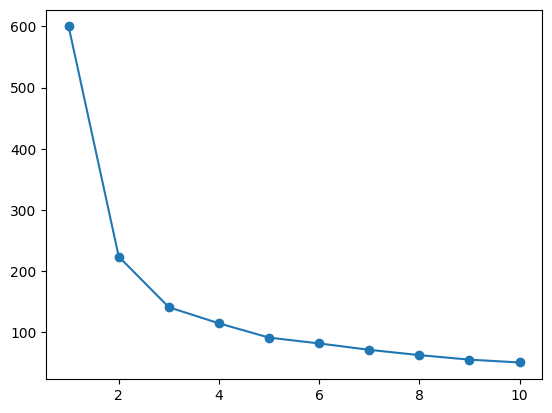

In [6]:
wcss_split = []

for k in np.arange(1, 11, 1):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X_scaled)
    wcss_split.append(km.inertia_)

plt.plot(range(1, 11), wcss_split, marker="o")

In [7]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(X_train)

train_labels = kmeans.predict(X_train)
test_labels = kmeans.predict(X_test)

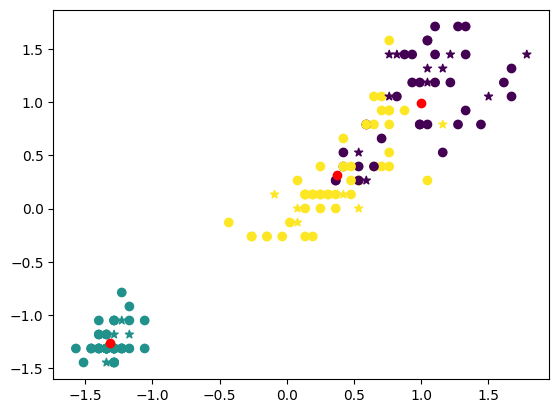

In [8]:
plt.scatter(X_train[:, 2], X_train[:, 3], c=train_labels)
plt.scatter(X_test[:, 2], X_test[:, 3], c=test_labels, marker="*")
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3], c="red")

plt.show()

In [9]:
# k means on full
km_labels = kmeans.predict(X_scaled)

print(pd.crosstab(species, km_labels, colnames=["Clusters"]))

Clusters          0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  11   0  39
Iris-virginica   33   0  17


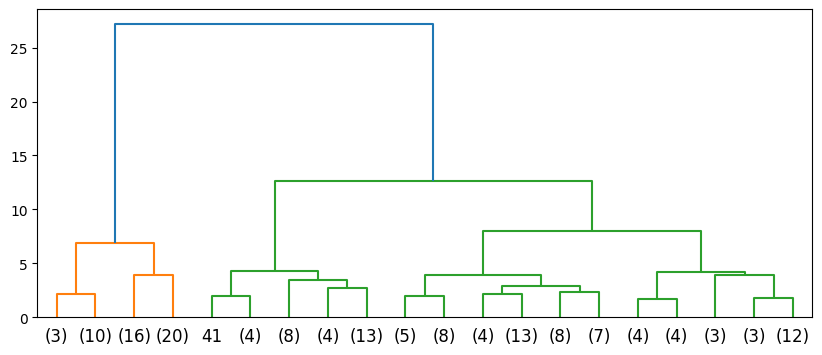

In [10]:
# Dendogram

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 4))

dendrogram(Z, truncate_mode="lastp", p=20)

plt.show()

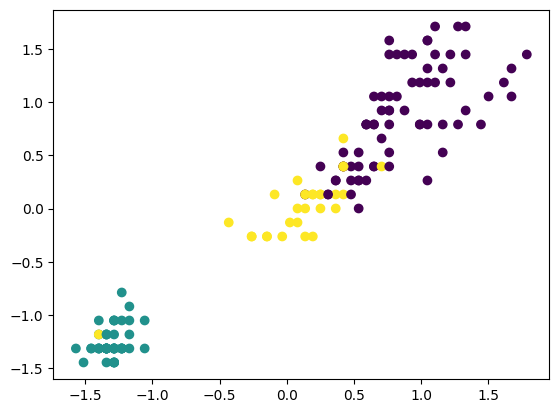

Hierarchical cluster   0   1   2
Species                         
Iris-setosa            0  49   1
Iris-versicolor       23   0  27
Iris-virginica        48   0   2


In [11]:
# agglomerative clustering

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
hc_labels = hc.fit_predict(X_scaled)

plt.scatter(X_scaled[:, 2], X_scaled[:, 3], c=hc_labels)

plt.show()

print(pd.crosstab(species, hc_labels, colnames=["Hierarchical cluster"]))

In [ ]:
def wcss(X, labels):
    total = 0
    for c in np.unique(labels):
        pts = X[labels == c]
        ctr = pts.mean(axis=0)
        total += np.sum((pts - ctr) ** 2)
    return total

def dunn(X, labels):
    clusters = [X[labels == c] for c in np.unique(labels)]
    gap = min(cdist(a, b).min() for i, a in enumerate(clusters) for b in clusters[i+1:])
    size = max(cdist(a, a).max() for a in clusters)
    return gap / size

                  WCSS    Gini   Dunn
Model                                
K-Means       141.1542  0.2679  0.057
Hierarchical  150.1223  0.2442  0.098


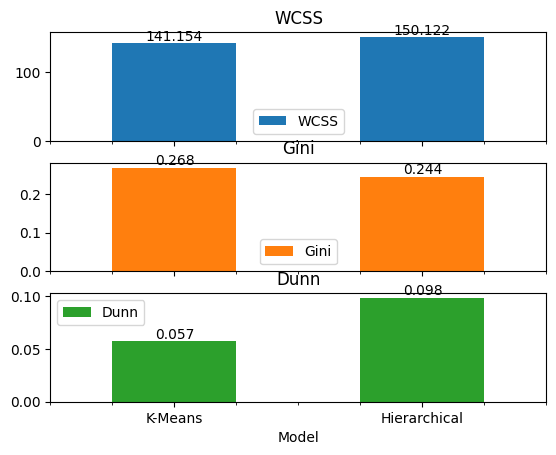

In [ ]:
results = []
for name, labels in [("K-Means", km_labels), ("Hierarchical", hc_labels)]:
    results.append({
        "Model": name,
        "WCSS": wcss(X_scaled, labels),
        "Dunn": dunn(X_scaled, labels),
    })

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

ax = results_df.plot(kind="bar", subplots=True, rot=0)
for a in ax.flatten():
    for bars in a.containers:
        a.bar_label(bars, fmt="%.3f")

plt.show()

In [ ]:
# predict cluster from user input (press Enter to use the average value)

feature_cols = df.drop(columns=["Id", "Species"]).columns
user = {}
for col in feature_cols:
    val = input(f"{col} [{df[col].mean():.2f}]: ").strip()
    user[col] = float(val) if val else df[col].mean()
user_scaled = scaler.transform(pd.DataFrame([user]))

# cluster number -> species that is most common in that cluster
km_map = pd.crosstab(km_labels, species).idxmax(axis=1)
hc_map = pd.crosstab(hc_labels, species).idxmax(axis=1)

km_c = kmeans.predict(user_scaled)[0]

# hierarchical has no predict(), so use the nearest cluster mean
hc_means = np.array([X_scaled[hc_labels == c].mean(axis=0) for c in np.unique(hc_labels)])
hc_c = cdist(user_scaled, hc_means).argmin()

print("\nInput:", user)
print(f"K-Means      -> cluster {km_c} (mostly {km_map[km_c]})")
print(f"Hierarchical -> cluster {hc_c} (mostly {hc_map[hc_c]})")